In [9]:
from typing import List, TypedDict
from langgraph.graph import StateGraph

In [10]:
class AgentState(TypedDict):
    name: str
    age: str
    skills: List[str]
    message: str


In [16]:
def greeting_node(state: AgentState) -> AgentState:
    state["message"] = f"Hallo {state['name']}"
    return state

def age_node(state: AgentState) -> AgentState:
    state["message"] = state["message"] + f", You are {state['age']} years old."
    return state

def skills_node(state: AgentState) -> AgentState:
    skills_str = ", ".join(state["skills"])
    state["message"] = state["message"] + f" Your skills are: {skills_str}."
    return state

In [17]:
graph = StateGraph(AgentState)

graph.add_node("greetor", greeting_node)
graph.add_node("ageor", age_node)
graph.add_node("skillsor", skills_node)

graph.set_entry_point("greetor")
graph.add_edge("greetor", "ageor")
graph.add_edge("ageor", "skillsor")

app = graph.compile()

In [18]:
message = app.invoke({"name": "Alice", "age": "30", "skills": ["Python", "JavaScript"], "message": ""})
print(message["message"])  # Output: 'Hallo Alice. You are 30 years old

Hallo Alice, You are 30 years old. Your skills are: Python, JavaScript.


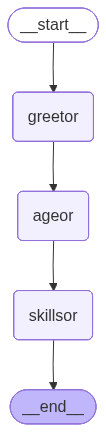

In [19]:
from IPython.display import Image, display
display(Image(app.get_graph().draw_mermaid_png()))